# BE1 . Data Science
### Identification des utilisateurs de Copilote à partir de leurs traces

**Bureau d'études réalisé par :**

* Hajar Zarguan
* Valentine Ponce
* Guillaume Sumian

### Objectif du projet

Ce projet vise à identifier les utilisateurs de Copilote à partir de leurs traces, en suivant trois étapes principales :

|  Étape | Description                                           |
| :----: | ----------------------------------------------------- |
| **01** | Analyse exploratoire des données                      |
| **02** | Construction et évaluation du modèle d'identification |
| **03** | Optimisation du modèle et analyse des performances    |


In [ ]:
import sys
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
src_path = "/home/valen/BE_DataSciences/src"

if src_path not in sys.path:
    sys.path.append(src_path)

import analyse_donnees as AN

### Lecture des données

In [ ]:
features_train = AN.read_ds("train")
features_test = AN.read_ds("test")
print(features_train.shape)

features_train["util"] = pd.Categorical(features_train["util"])
features_train[["util","navigateur"]].describe()

(3279, 14470)


,util,navigateur
count,3279,3279
unique,247,4
top,skm,Firefox
freq,75,1466


# Utilisation des navigateurs

In [3]:
# Nouvelle Dataframe
updated_df = pd.DataFrame({'util':features_train["util"].unique()})
updated_df["util"] = pd.Categorical(updated_df["util"])

top: most frequent value in the column
freq: Frequency of the most common value

Nombre maximum de navigateurs utilisés par un utilisateur: 1
                sessions  part (%)  utilisateurs l'ayant utilisé
navigateur                                                      
Firefox             1466     44.71                           114
Google Chrome       1339     40.84                            93
Microsoft Edge       451     13.75                            39
Opera                 23      0.70                             1


,util,navigateur
0,aho,1
1,ajo,0
2,akx,1
3,ald,1
4,ats,0


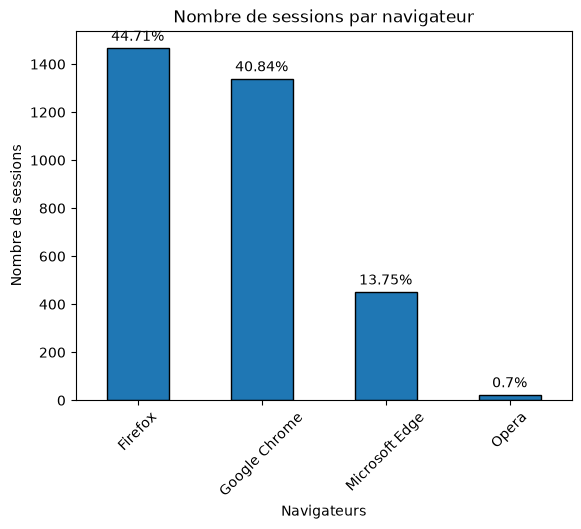

In [4]:
# Utilisateur utilise toujours le même navigateur
df_navigateurs = AN.browsers_analysis(features_train)
print(df_navigateurs)

updated_df = features_train[["util","navigateur"]].groupby("util")["navigateur"].first().reset_index()
updated_df = AN.to_categories(updated_df,"navigateur")
updated_df.head()

In [5]:
uniques = features_train.iloc[:,2:].stack().unique()
filtered_uniques = list(set([AN.filter_action(un) for un in uniques if isinstance(un, str) and not un.startswith("t")]))
len(filtered_uniques)

updated_df = AN.actions_analysis(features_train,updated_df,filtered_uniques)
updated_df.head()



,util,navigateur,mean_Action de table,mean_Affichage d'un toast,mean_Affichage d'une arborescence,mean_Affichage d'une dialogue,mean_Affichage d'une erreur,mean_Chainage,mean_Clic long,mean_Clic sur une checkbox,...,mean_Lancement d'une stat,mean_Ouverture d'un panel,mean_Raccourci,mean_Raccourci dans l'édition de table,mean_Retour sur un écran,mean_Saisie dans un champ,mean_Sélection d'un flag,mean_Sélection d'un écran,mean_Sélection d'un élément,mean_Sélection d’un onglet
0,aho,1,7.300000,3.800000,2.700000,53.100000,1.400000,18.700000,0.000000,2.200000,...,1.700000,0.700000,29.700000,0.0,6.400000,163.600000,0.000000,48.300000,5.800000,11.400000
1,ajo,0,23.153846,12.846154,23.230769,82.692308,4.384615,31.692308,0.153846,25.769231,...,28.692308,4.076923,162.692308,0.0,100.923077,115.692308,0.000000,112.538462,8.846154,77.923077
2,akx,1,8.428571,3.642857,1.500000,24.214286,1.142857,3.571429,0.000000,3.928571,...,0.500000,0.571429,59.785714,0.0,2.428571,42.857143,0.000000,16.642857,68.928571,5.571429
3,ald,1,9.733333,5.133333,2.266667,61.266667,3.333333,24.933333,0.266667,4.333333,...,23.866667,0.200000,33.933333,0.0,8.133333,118.333333,0.333333,92.866667,14.933333,37.333333
4,ats,0,6.333333,7.416667,7.083333,48.250000,5.333333,15.416667,0.000000,10.583333,...,2.000000,0.333333,12.416667,0.0,3.583333,83.916667,0.083333,71.333333,8.416667,11.833333


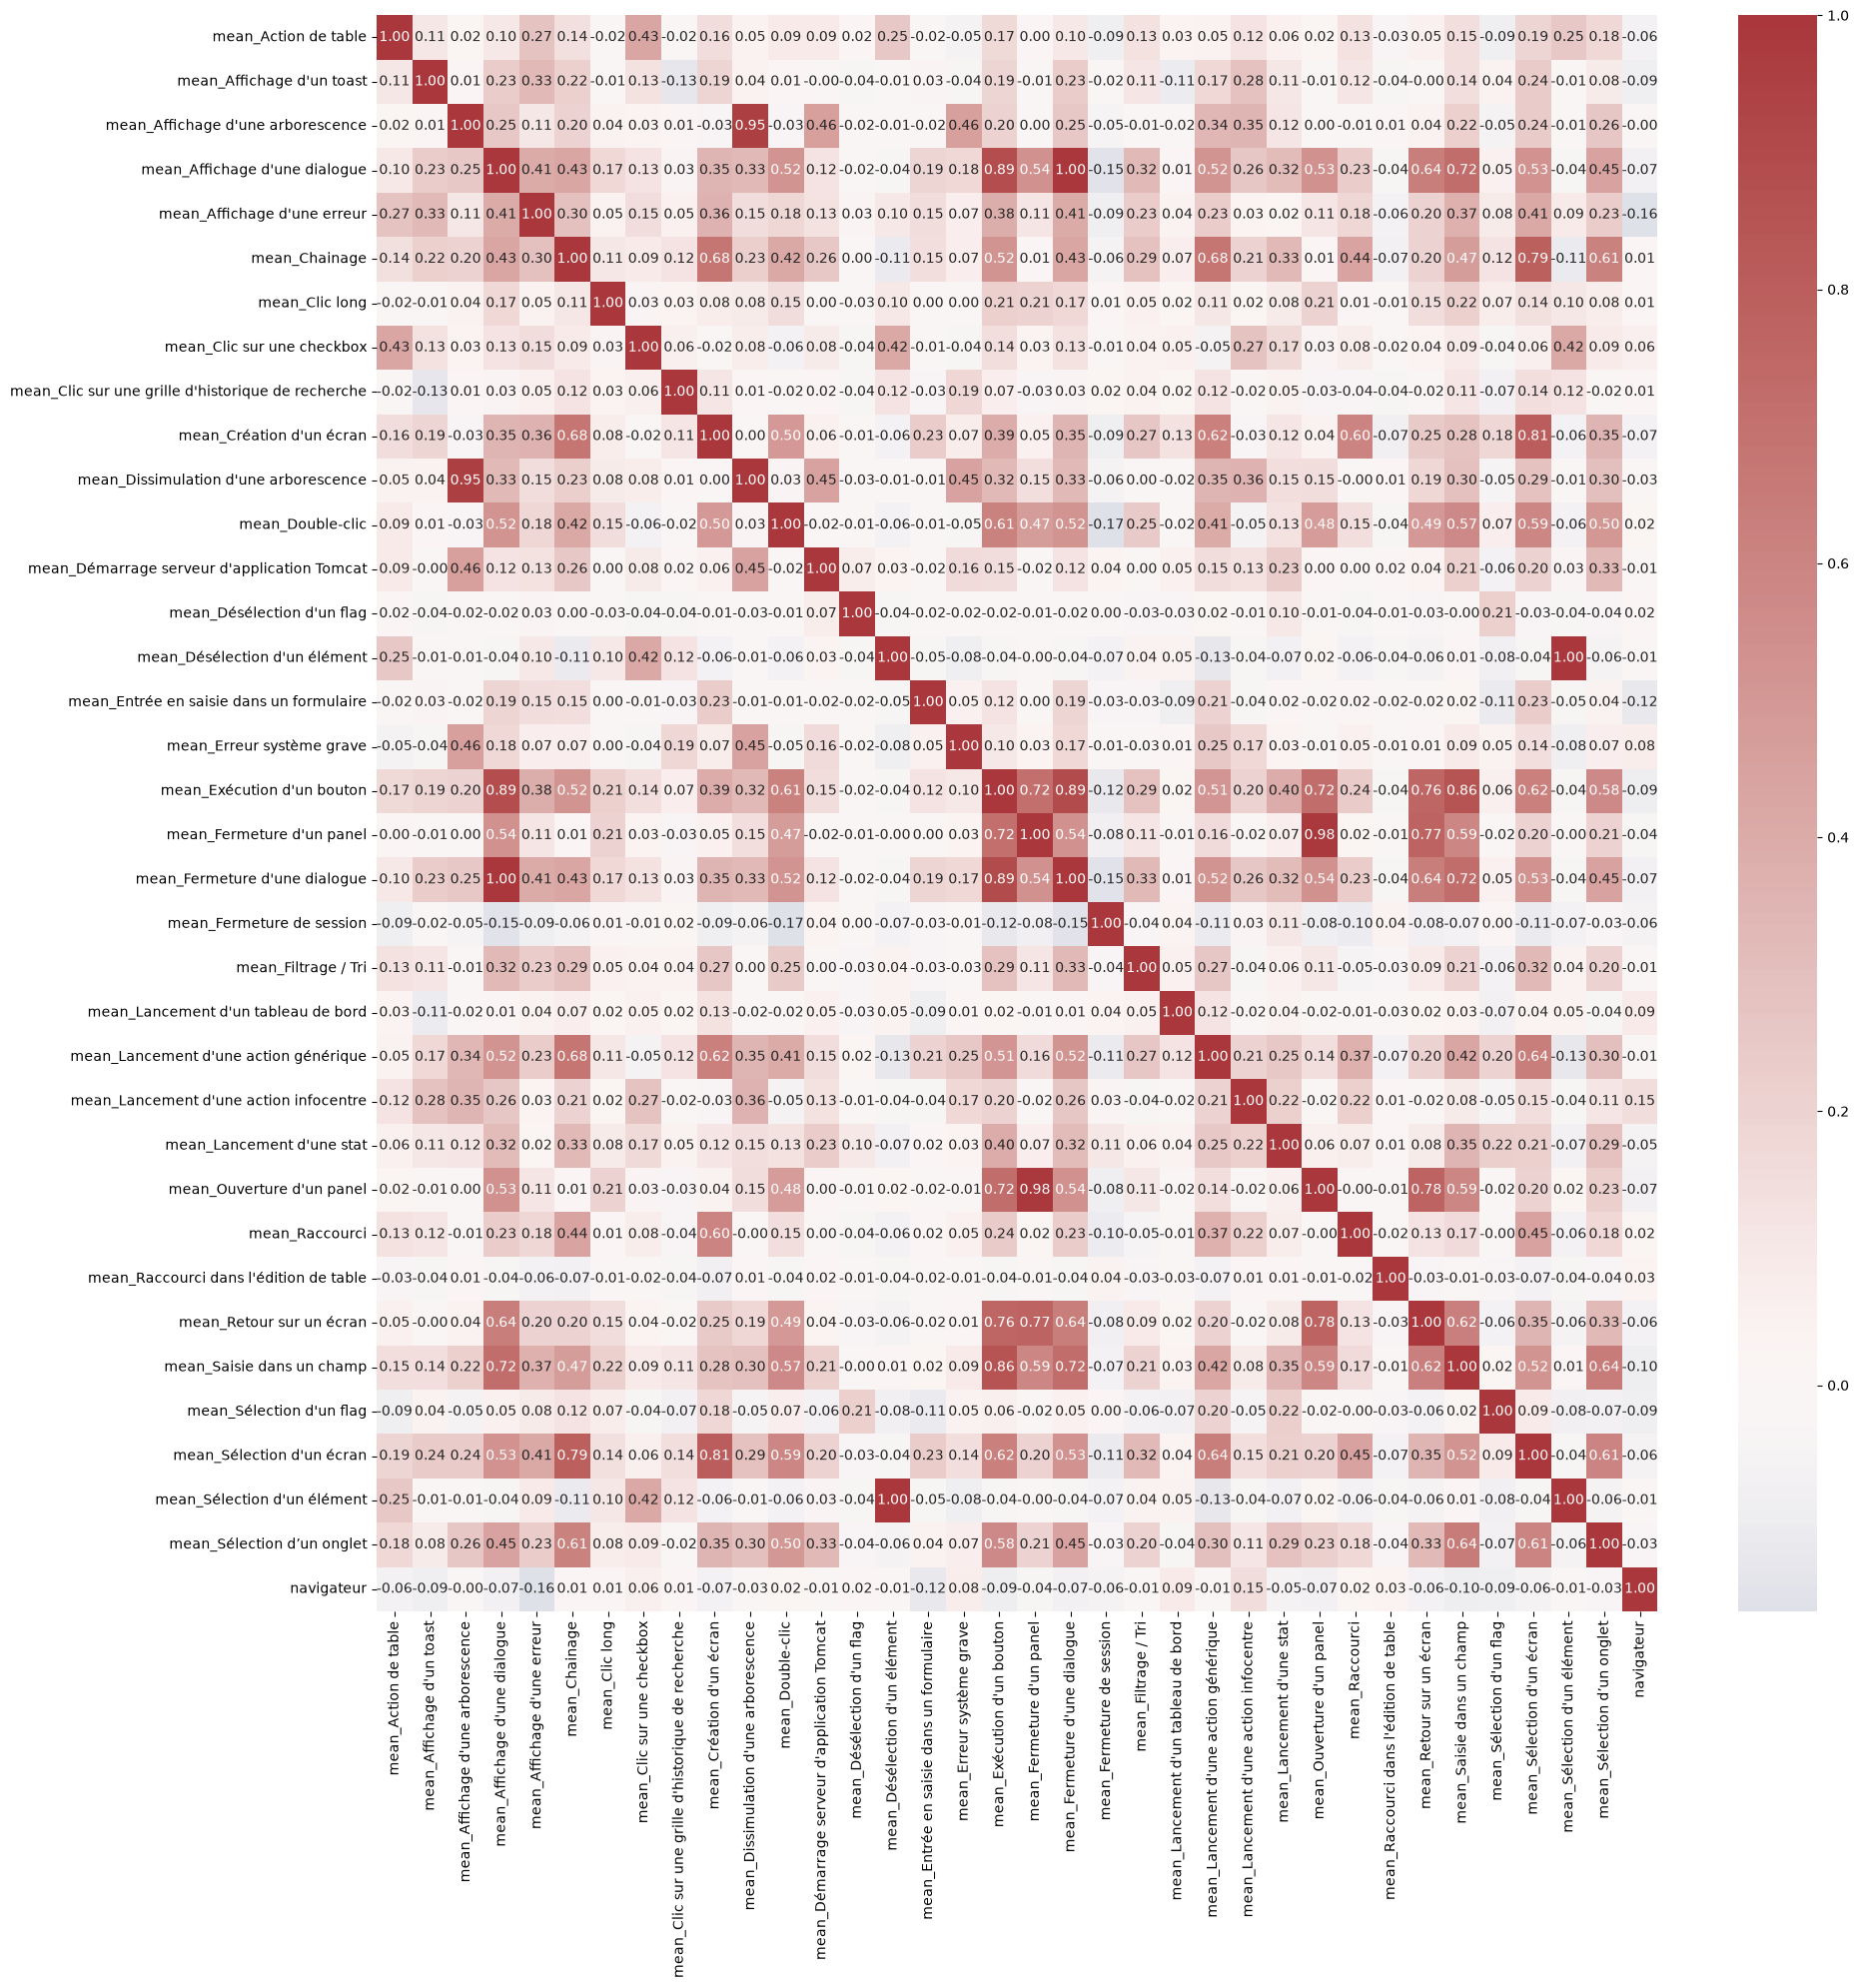

In [6]:
cols_actions = updated_df.columns.difference(["util"])

corr = updated_df[cols_actions].corr()

fig, ax = plt.subplots(figsize=(20, 20))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
fig.tight_layout()

  util  navigateur  mean_Action de table  mean_Affichage d'un toast  \
0  aho           1              7.300000                   3.800000   
1  ajo           0             23.153846                  12.846154   
2  akx           1              8.428571                   3.642857   
3  ald           1              9.733333                   5.133333   
4  ats           0              6.333333                   7.416667   

   mean_Affichage d'une arborescence  mean_Affichage d'une dialogue  \
0                           2.700000                      53.100000   
1                          23.230769                      82.692308   
2                           1.500000                      24.214286   
3                           2.266667                      61.266667   
4                           7.083333                      48.250000   

   mean_Affichage d'une erreur  mean_Chainage  mean_Clic long  \
0                     1.400000      18.700000        0.000000   
1               

Text(0, 0.5, 'Fréquence')

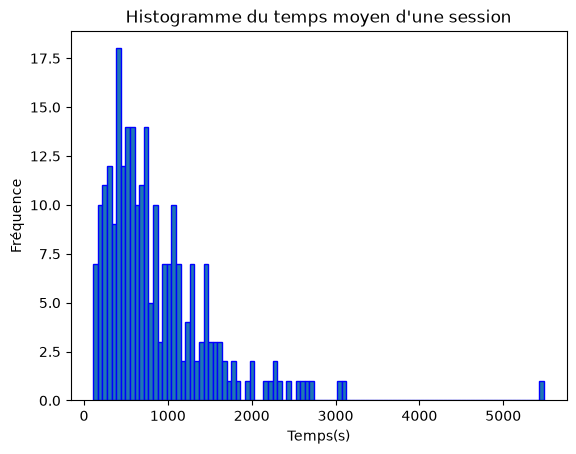

In [7]:
updated_df = AN.temps_par_session(features_train,updated_df)
print(updated_df.head())

max_val = updated_df["max_t"].max()
bin_width = 120 # 60: regroupe par minute, 300 regroupe par 5 min
print(f"Plus longue session: {max_val}")
ax = updated_df["moyenne_t"].plot.hist(bins=int(max_val/bin_width),edgecolor="blue")
ax.set_title("Histogramme du temps moyen d'une session")
ax.set_xlabel("Temps(s)")
ax.set_ylabel("Fréquence")
#updated_df["moyenne_t"].hist(bins="fd",edgecolor="blue")

<Axes: >

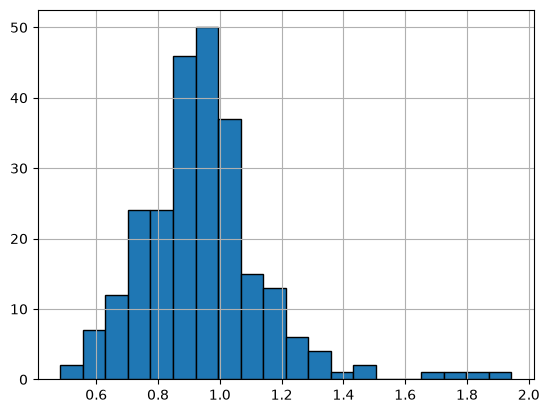

In [8]:
df = AN.rapidite_util(features_train,updated_df)
df["rapidite"].hist(bins=20, edgecolor="black")


In [9]:
updated_df = AN.stat_actions(features_train,updated_df)
updated_df.head()

,util,navigateur,mean_Action de table,mean_Affichage d'un toast,mean_Affichage d'une arborescence,mean_Affichage d'une dialogue,mean_Affichage d'une erreur,mean_Chainage,mean_Clic long,mean_Clic sur une checkbox,...,mean_fiche,std_fiche,min_ecran,max_ecran,mean_ecran,std_ecran,min_changement_ecran,max_changement_ecran,mean_changement_ecran,std_changement_ecran
0,aho,1,7.300000,3.800000,2.700000,53.100000,1.400000,18.700000,0.000000,2.200000,...,58.400000,56.228107,19,212,90.200000,72.651069,7,120,46.300000,38.841702
1,ajo,0,23.153846,12.846154,23.230769,82.692308,4.384615,31.692308,0.153846,25.769231,...,24.538462,25.078594,20,309,174.153846,86.272674,9,158,83.000000,46.173586
2,akx,1,8.428571,3.642857,1.500000,24.214286,1.142857,3.571429,0.000000,3.928571,...,19.214286,31.657247,3,84,28.571429,23.190563,1,44,14.214286,13.250130
3,ald,1,9.733333,5.133333,2.266667,61.266667,3.333333,24.933333,0.266667,4.333333,...,132.600000,209.383380,6,374,117.000000,118.628472,2,120,34.666667,38.066984
4,ats,0,6.333333,7.416667,7.083333,48.250000,5.333333,15.416667,0.000000,10.583333,...,85.166667,93.180015,13,369,92.500000,96.035505,6,236,59.583333,62.171988


array([[<Axes: title={'center': 'mean_changement_ecran'}>,
        <Axes: title={'center': 'mean_ecran'}>],
       [<Axes: title={'center': 'mean_fiche'}>,
        <Axes: title={'center': 'mean_modif'}>]], dtype=object)

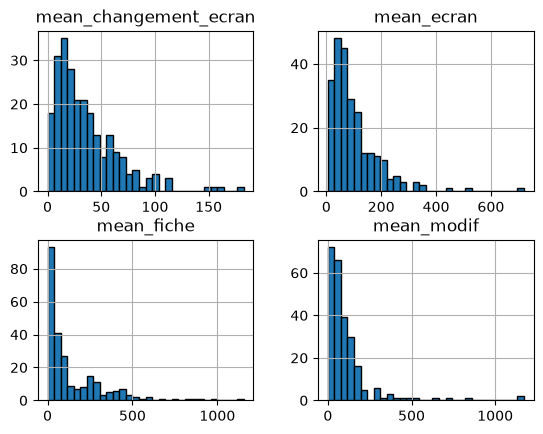

In [10]:
updated_df[["mean_changement_ecran","mean_ecran","mean_fiche","mean_modif"]].hist(bins=30, edgecolor="black")